---
## **0. 준비**
---

In [1]:
%%html
<style>
    body {
        /* change --vscode-font-family if it's different on your system */
        --vscode-font-family: "SeoulNamsanC";
    }
</style>

In [1]:
from langchain_openai import ChatOpenAI
from langchain_google_genai import GoogleGenerativeAI

In [2]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

In [3]:
import config
config.set_environment()

---
## **LangGraph의 기본 원리**
---

- LangGraph는 LangChain 회사에서 개발한 워크플로 제어 및 오케스트레이션 프레임워크임.
- 별도의 워크프레임이 필요한 이유는 에이전트 기반 워크플로 구성에서 알 수 있을 것.
- **LangGraph 요약 :**
    - 비순환 그래프(DAG)가 아니라, **순환 주기를 허용**
    - 기본적으로 **스트리밍을 지원**
    - 생성형 AI에 특화된 **미리 제작된 루프와 컴포넌트**(예. 인간 중재 기능 등)를 제공
    - **세분화된 실행 흐름 제어**가 가능한 풍부한 API

- (참고) 방향성 비순환 그래프(DAG, Directed Acyclic Graph)
    - 그래프의 에지(노드 간 연결선)는 방향성을 가지며, **노드 A에서 B로의 연결과 노드 B에서 A로의 연결이 서로 다름**
    - DAG는 순환 구조를 갖지 않음
    - 즉, 어떤 노드에서 시작해 방향성 에지를 따라 이동했을 때 **다시 같은 노드로 돌아오는 경로가 존재하지 않음**
    - DAG는 데이터 엔지니어링 워크플로 모델로 자주 사용 : 노드는 작업(task)을 나타내고, 에지는 작업 간의 의존 관계를 나타냄. 예를 들어, A -> B는 노드 B를 실행하려면 노드 A의 출력이 필요하다는 뜻. 

---
### **상태 관리(state management)**
- '그래프(graph)'와 '워크플로' 용어를 동일한 의미로 사용하자.
- 그래프는 노드와 노드간의 에지로 구성, **노드는 워크플로의 컴포넌트이며, 워크플로는 상태(state)를 갖음**
- **상태(state) :**
    1. 상태는 사용자 입력과 이전 계산 결과를 추적하여 노드(워크플로의 컴퍼넌트)들이 현재 상황을 인지하도록 함
    2. 상태를 통해 워크플로 실행을 언제든지 중단하고 저장할 수 있음
    3. 노드(워크플로의 컴퍼넌트)가 상태를 업데이트하면 워크플로 동작을 변경할 수 있기 때문에, 상태는 워크플로를 진정한 상호작용형으로 만듦
    - **간단히 말해서, 상태를 파이썬 딕셔너리라고 생각하면 된다. 노드(컴퍼넌트)는 이 딕셔너리를 처리하는 파이썬 함수다. 노드는 딕셔너리를 입력으로 받아서 워크플로의 상태에서 업데이트할 키와 값을 포함한 새로운 딕셔너리를 반환**

In [ ]:
# 간단한 예제: 노드들이 공유할 상태의 키 이름과 값의 타입을 정의합니다.
# 스키마는 데이터의 설계도입니다. 이 셀에서는 실제 공고나 지원서 내용을 생성하지 않습니다.

from typing import TypedDict                                                #딕셔너리의 키별로 서로 다른 값의 타입을 명시할 수 있는 TypedDict을 로딩

# TypedDict를 기반으로 상태 스키마를 선언합니다. 실제 상태 값은 일반 파이썬 딕셔너리입니다.
# 타입 힌트는 정적 분석을 돕지만, TypedDict 자체가 실행 중 값의 타입을 검사하거나 변환하지는 않습니다.
class JobApplicationState(TypedDict):
    job_description: str    #채용 공고 원문을 담는 문자열 키. 그래프 실행 시 입력으로 전달하고 분석 노드가 읽게 됨.
    is_suitable: bool       #공고의 적합 여부를 담는 불리언(True/False) 키. 분석 노드가 계산해 갱신.
    application: str        #생성된 지원서 내용을 담는 문자열 키. 지원서 생성 노드가 갱신.

# 위의 ': str', ': bool'은 타입 선언이며 기본값 대입이 아닙니다. 키에 값이 자동으로 채워지지 않습니다.
# 기본 TypedDict는 정적 타입 검사에서 세 키를 모두 요구합니다(total=True가 기본값).
# 다만 LangGraph는 입력으로 상태의 일부 키를 받고, 이후 노드가 나머지 키를 채우는 실행을 지원합니다.
# 예: graph.invoke({"job_description": "채용 공고 내용"}) — graph를 만든 다음 셀 이후에 실행합니다.
# 아직 채워지지 않은 키를 노드에서 state["키"]로 읽으면 KeyError가 발생할 수 있습니다.


> - `TypedDict`는 파이썬의 타입 생성자로, **미리 정의된 키 집합을 가진 딕셔너리를 정의함**
> - **각 키는 고유한 타입을 가질 수 있으며**, Dict[str, str]처럼 모든 값이 동일한 일반 딕셔너리와 다름
> - **LangGraph의 상태 스키마는 TypedDict 외에도 데이터 클래스나 Pydantic 모델을 사용해 정의할 수 있음**

In [19]:
# 스키마를 정의했으니 간단한 워크플로를 구성해보자
"""
- 2개의 파이썬 함수를 워크플로의 컴퍼넌트(노드)로 만듦
- 상태 스키마를 정의 -> 노드와 에지를 추가
"""

from langgraph.graph import StateGraph, START, END                          #StateGraph는 상태를 공유하는 그래프의 설계 도구

# 첫 번째 노드 함수, 실행 시점의 그래프 상태 딕셔너리를 state 인자로 전달받음.
def analyze_job_description(state):
    print("...Analyzing a provided job description...")
    return {"is_suitable": len(state["job_description"])>100}               #공고 문자열의 길이가 100자를 초과하면 True, 아니면 False를 반환, 전체 상태를 다시 반환할 필요 없이 변경할 키만 반환, 여기서는 is_suitable 값을 갱신.

# 두 번째 노드 함수, 앞 노드의 결과가 반영된 상태를 받음
def generate_application(state):
    print("...generating application...")
    return {"application": "some_fake_application"}                         #실제 지원서를 생성하는 대신 고정된 예시 문자열을 application 키의 새 값으로 반환.

# 앞 셀에서 정의한 JobApplicationState를 상태 스키마로 지정하여 그래프 설계 객체를 만듦.
builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)        #첫 번째 인자는 그래프에서 사용할 노드 이름, 두 번째 인자는 실행할 함수 객체, 함수 이름 뒤에 ()를 붙이지 않음 -> 지금 호출하는 것이 아니라 실행할 함수를 등록하기 때문.
builder.add_node("generate_application", generate_application)

builder.add_edge(START, "analyze_job_description")                          #그래프 실행이 시작되면 공고 분석 노드로 이동하도록 연결.
builder.add_edge("analyze_job_description", "generate_application")         #분석이 끝나면 지원서 생성 노드로 무조건 이동. is_suitable이 False여도 생성 노드는 실행, 적합 여부에 따라 실행을 나누려면 별도로 조건부 에지(add_conditional_edges)를 구성해야 함.
builder.add_edge("generate_application", END)                               #지원서 생성 노드가 끝나면 워크플로를 종료.

# 설계한 노드와 연결을 검사하고 실행 가능한 그래프로 만듦. compile() 자체는 노드를 실행하지 않습니다.
graph = builder.compile()                                                   #이후 graph.invoke({"job_description": "공고 내용"})를 호출하면 위 순서로 실행하고 최종 상태를 반환.


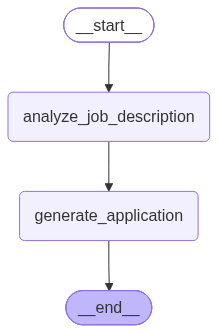

In [20]:
# 워크플로 시각화
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

> - 노드가 상태를 바꾸려면, 반드시 업데이트할 키와 값이 들어 있는 딕셔너리를 반환해야함.
> - 노드는 상태에서 최소한 하나의 키를 수정해야함. 

In [21]:
# graph 인스턴스 자체는 Runnable(정확히는 Runnable을 상속). 
# 초기 상태를 딕셔너리로 넘기면, 실행 결과로 최종 상태를 딕셔너리 형태로 받을 수 있음
res = graph.invoke({"job_description": "fake_jd"})
print(res)

...Analyzing a provided job description...
...generating application...
{'job_description': 'fake_jd', 'is_suitable': False, 'application': 'some_fake_application'}


- LangGraph는 워크플로를 **슈퍼스텝**이라는 단위로 실행
- **슈퍼스텝은 여러 개의 노드를 대상으로 한 하나의 반복 실행 단위를 의미**
- 슈퍼스텝은 여러 노드를 병렬로 실행하고, 그 결과를 중앙 그래프 상태에 반영하는 역할을 함

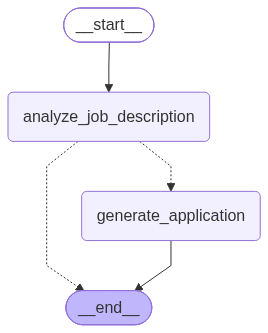

...Analyzing a provided job description...
{'job_description': 'fake_jd', 'is_suitable': False}


In [ ]:
# 조건부 에지 실습으로 발전
# 현재 상태에 따라 실행 흐름을 다른 노드로 동적으로 전달 가능
# 조건부 에지는 현재 상태를 입력받아 실행할 노드의 이름을 문자열로 반환하는 파이썬 함수

from typing import Literal

builder = StateGraph(JobApplicationState)
builder.add_node("analyze_job_description", analyze_job_description)
builder.add_node("generate_application", generate_application)

def is_suitable_condition(state: JobApplicationState) -> Literal["generate_application", END]:
    if state.get("is_suitable"):
        return "generate_application"
    return END

builder.add_edge(START, "analyze_job_description")
builder.add_conditional_edges("analyze_job_description",
                             is_suitable_condition)
builder.add_edge("generate_application", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

res = graph.invoke({"job_description": "fake_jd"})                          #위 예시에서는 generate_application 노드를 거치지 않고 바로 END로 진행 -> 'application' 키와 값이 반환되지 않음(둘다 없는 거임)
print(res)

말씀하신 실행에서 **초기 입력에도 `application`을 넣지 않았고, 생성 노드도 거치지 않았다면 최종 딕셔너리에는 키와 값이 모두 없습니다.**

```python
{"job_description": "fake_jd", "is_suitable": False}
```

상태 스키마의 다음 선언은 **사용할 키와 타입을 정의할 뿐, 실제 키나 기본값을 생성하지 않습니다.**

```python
application: str
```

다음 세 상태는 서로 다릅니다.

| 상태 | 딕셔너리 표현 |
|---|---|
| 키가 없음 | `{}` |
| 키가 있고 값이 `None` | `{"application": None}` |
| 키가 있고 값이 빈 문자열 | `{"application": ""}` |

따라서 지금 상황은 **스키마에는 `application`이 정의되어 있지만, 이번 실행에서는 값이 입력·생성되지 않아 최종 상태에 해당 키가 없다**고 서술하면 정확.

```python
"application" in result  # 키 존재 여부 확인
```

단, 처음부터 `application` 값을 입력했다면 생성 노드를 건너뛰어도 기존 값은 유지됩니다.

현재 저장된 파일에는 아직 이전 오타와 코드가 남아 있어, 최신 출력 자체는 확인하지 못했습니다.

> - Literal 타입 힌트를 사용했는데, 이는 LagnGraph가 조건부 에지를 생성할 때 어떤 목적지 노드와 연결할지 판단할 때 사용
> - **만약 타입 힌트를 사용하지 않으면, `add_conditional_edges` 함수에 목적지 노드들의 목록을 직접 넘겨야함**
> - 타입 힌트도 없고 목적지도 명시하지 않으면, LangGraph는 소스 노드를 그래프에 있는 모든 노드와 연결하게 됨

---
### **리듀서**

In [ ]:
# Ollama를 LCEL 패턴과 통합하는 방법 학습
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

# 선택한 모델로 Ollama 초기화
local_llm = ChatOllama(
    model = "qwen3.5:4B",
    base_url="http://172.30.128.1:11434",
    temperature=0,
)

# 로컬 모델을 사용하는 LECL 체인 생성
prompt = PromptTemplate.from_template("단순한 용어로 {concept}을 설명하라.")
local_chain = prompt | local_llm | StrOutputParser()

# 로컬 모델 체인 사용
result = local_chain.invoke({"concept": "양자 컴퓨팅"})
print(result)

---
### **로컬에서 Hugging Face 모델 작업**
- 허깅페이스는 모델 실행을 위한 두 가지 주요 방식을 지원
    - 로컬 환경에서 직접 실행하는 HuggingFacePipeline
    - 클라우드 기반 Hugging Face Hub를 통해 실행하는 HuggingFaceEndpoint
- 해당 실습에서는 로컬 실행 방식에 집중

In [ ]:
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_huggingface import ChatHuggingFace, HuggingFacePipeline

# 소형 모델 파이프라인 생성
llm = HuggingFacePipeline.from_model_id(
    model_id = "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    task = "text-generation",
    pipeline_kwargs= dict(
        max_new_tokens=512,
        do_sample=False,
        repetition_penalty=1.03,
    ),
)

chat_model = ChatHuggingFace(llm=llm)

# 다른 LangChain LLM과 동일한 방식 사용
messages = [
    SystemMessage(content="You're a helpful assistant"),
    HumanMessage(content= "양자 컴퓨팅에 대해 설명해주세요."),
]
ai_msg = chat_model.invoke(messages)
print(ai_msg.content)

---
### **로컬 모델을 위한 팁**
- 로컬 모델로 작업을 시작하면 성능 최적화와 일반적인 문제 해결이 필요.
- 다음 사항을 고려해야함.

<hr style="border:0;border-top:1.5px dashed gray;">

#### **1. 리소스 관리**
- 로컬 모델은 성능과 리소스 사용량을 균형있게 조절 필요
- 다음은 Ollama 모델을 효율적으로 운영하기 위한 구성 예시

In [ ]:
# 메모리, 연산 설정 최적화 모델 구성
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model= "qwen3.5:4b-q4_K_M",                                             #4비트 양자화 모델(메모리 사용량 감소)
    base_url="http://172.30.128.1:11434",                                                
    num_gpu=1,                                                              #사용할 GPU 개수(하드웨어에 따라 조정)
    num_thread=4,                                                           #병렬 처리용 CPUa 스레드 수 설정
    #temperature=0,                                                            
    #num_ctx=4096,                                                          #짧은 실습부터 시작해 메모리 사용량 제한               
)

- **`model="mistral:q4_K_M"`** : 4비트 양자화된 모델 지정, 양자화는 모델의 가중치를 더 적은 비트로 표현 -> 약간의 정확도는 손실되지만 메모리 크게 절약 가능
- **`num_gpu=1`** : GPU 리소스를 할당
    - 0 : CPU 전용 모드(GPU 없이 실행되나 속도 저하)
    - 1 : 단일 GPU 사용(일반 테스크톱 환경에 적합)
    - 더 높은 값 : 멀티 GPU 시스템용
- **`num_thread=4`** : CPU 병렬 처리를 제어
    - 낮은값(2-4) : 다른 프로그램과의 동시 실행에 적합
    - 높은값(8-16) : 전용 서버에서 최대 성능을 발휘
    - 최적값 : CPU의 물리적 코어 수에 맞추는 것이 좋음

In [ ]:
# 로컬 모델을 사용하는 LECL 체인 생성
prompt = PromptTemplate.from_template("단순한 용어로 {concept}을 설명하라.")
local_chain = prompt | llm | StrOutputParser()

# 로컬 모델 체인 사용
result = local_chain.invoke({"concept": "양자 컴퓨팅"})
print(result)

<hr style="border:0;border-top:1.5px dashed gray;">

#### **2. 오류 처리**
- 로컬 모델은 메모리 부족이나 예기치 않은 종료와 같은 다양한 오류가 발생할 수 있으므로 강력한 오류 처리 전략이 필수

In [ ]:
# 아래 코드 시간상 실제 실행-검증은 하지 않았음
import time

def safe_model_call(llm, prompt, max_retries=2):
    """재시도 로직과 안정적인 오류 대응을 갖춘 모델 안전 호출 함수"""
    retries = 0
    while retries <= max_retries:
        try:
            return llm.invoke(prompt)
        except RuntimeError as e:
            # VRAM 부족으로 로컬 모델 호출 중 자주 발생하는 오류
            if "CUDA out of memory in str(e)":
                print(f"GPU 메모리 에러, waiting and retrying ({retries+1}/{max_retries+1})")
                time.sleep(2) #시스템이 리소스를 해제할 시간을 줌
                retries += 1
            else:
                print(f"Runtime error: {e}")
                return "An error occured while processing your request."
        except Exception as e:
            print(f"Unexpected error calling model: {e}")
            return "An error occurred while processing your request."
        
        # 재시도 횟수를 모두 소진한 경우
        return "Model is currentrly experiencing high load. Please try again later."

# LECL chain에 안전 wrapper를 사용
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnableLambda

prompt = PromptTemplate.from_template("단순한 용어로 {concept}을 설명하라.")
safe_llm = RunnableLambda(lambda x: safe_model_call(llm, x))
safe_chain = prompt | safe_llm
response = safe_chain.invoke({"concept": "양자 컴퓨팅"})
            

로컬 모델 사용 시 일반적으로 주요 오류는 다음과 같다.
- **메모리 부족** : 모델이 사용 가능한 VRAM을 초과하여 요구하는 경우
- **모델 로딩 실패** : 모델 파일이 손상되었거나 호환성 문제가 있는 경우
- **시간 초과** : 제한된 시스템 리소스로 인해 추론 시간이 지나치게 길어지는 경우
- **컨텍스트 길이 초과** : 입력이 모델의 최대 토근 제한을 넘어서는 경우


---
## **멀티모달 AI 애플리케이션(Skip)**
---